## Import Libraries and Tools

In [7]:
import os
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd
import PIL.Image as Image
import PIL.ImageEnhance as ImageEnhance

# keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout
from tensorflow.keras.utils import load_img
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle


## Local Dataset

In [8]:
train_dir = '/home/nishanta/Projects/MRI_Detection/dataset/Training'
test_dir = '/home/nishanta/Projects/MRI_Detection/dataset/Testing'


# Load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)


# Load and shuffle the test data
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)


## Data Visualization

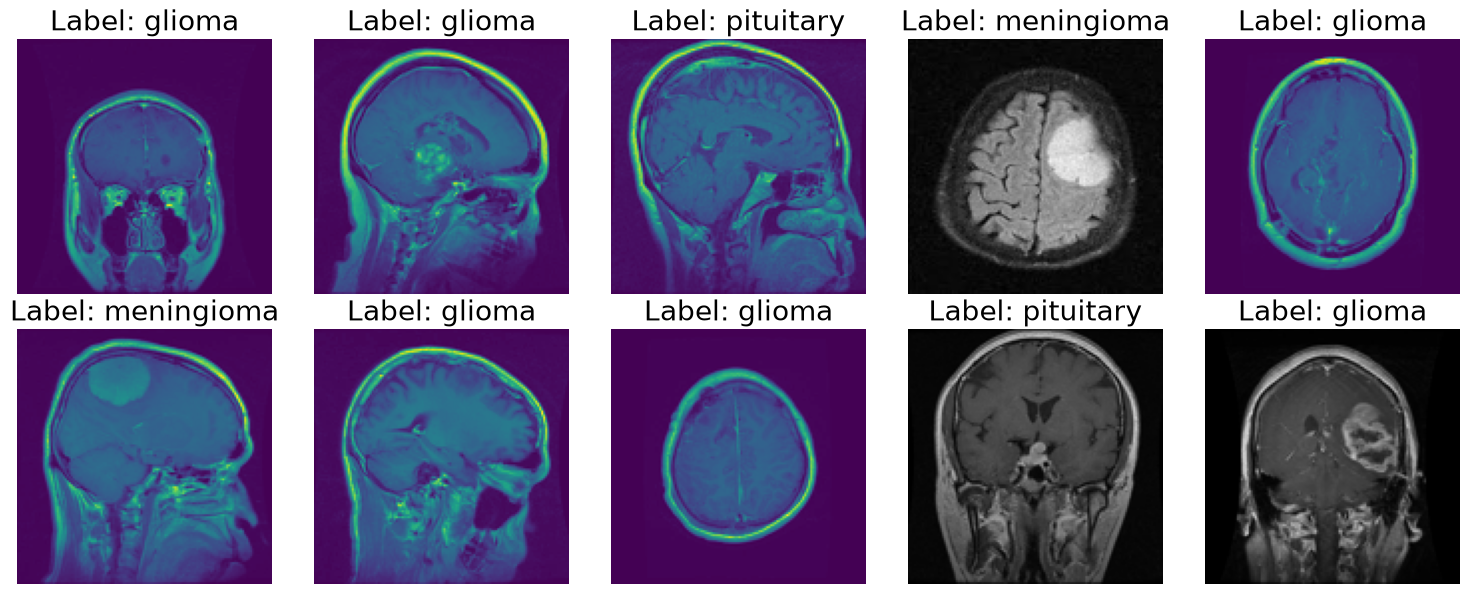

In [9]:
import random
import matplotlib.pyplot as plt

random_indices = random.sample(range(len(train_paths)),10)
random_indices

# Create a figure to display 10 images in 2 rows
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

# Loop through the random indices and display the images
for i, idx in enumerate(random_indices):
    img_path = train_paths[idx]
    img = Image.open(img_path)
    img = img.resize((128, 128))  # Resize the image to 128x128

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Label: {train_labels[idx]}", fontsize=20)

plt.tight_layout()
plt.show()

## Image Preprocessing (Helper Function)

In [10]:
IMAGE_SIZE = 128
# Image augumentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image)) # convert to PIL image
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    image = np.array(image)/255.0 # normalize the image
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        img = augment_image(img)
        images.append(img)
    return np.array(images)

# Encoder Labels (Convert label names into integers)
def encode_labels(labels):
    unique_labels = os.listdir(train_dir)
    encoded = [unique_labels.index(label) for label in labels]
    return encoded

# Data generator for batching 
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i+batch_size]
            batch_images = open_images(batch_paths)
            batch_labels = labels[i:i+batch_size]
            batch_labels = np.asarray(encode_labels(batch_labels), dtype=np.int32)
            yield batch_images, batch_labels

## Model Architecture (VGG16)

In [16]:
IMAGE_SIZE = 128
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

# Freeze all the layers of the VGG16 base model
for layer in base_model.layers:
    layer.trainable = False

# Set only the last few layers to be trainable
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

# Build the final model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))) # Input Layer
model.add(base_model) # VGG16 Base Model
model.add(Flatten()) # Flatten the output of the base model
model.add(Dropout(0.3)) # Dropout layer for regularization

model.add(Dense(128, activation='relu')) # Fully connected layer with 128 units
model.add(Dropout(0.2))

model.add(Dense(len(os.listdir(train_dir)), activation='softmax')) # Output layer with softmax activation for multi-class classification


# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

# Paramerters for training
batch_size = 20
steps = (len(train_paths) + batch_size - 1) // batch_size
epochs = 5

# train the model
history = model.fit(
    datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
    steps_per_epoch=steps,
    epochs=epochs,
)



Epoch 1/5


/home/nishanta/Projects/MRI_Detection/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792863495.890107   51432 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


257/280 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - loss: 0.4874 - sparse_categorical_accuracy: 0.8134

KeyboardInterrupt: 

In [6]:
os.listdir(train_dir)
len(os.listdir(train_dir))

4

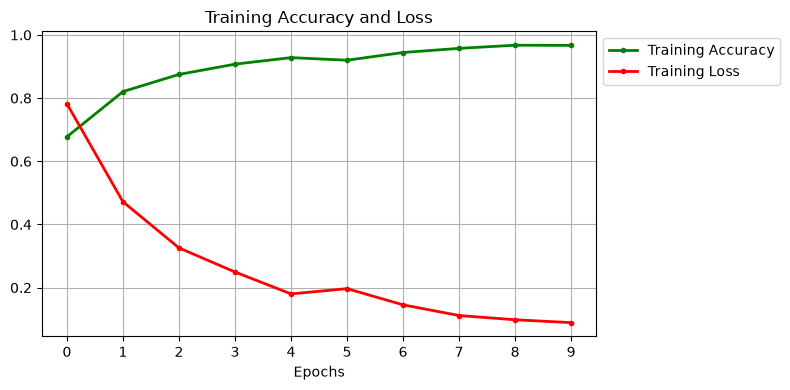

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Load metrics from CSV
df = pd.read_csv("VGG16_model/metrics.csv")

# Number of epochs
epochs = len(df)

# Plot accuracy and loss
plt.figure(figsize=(8, 4))
plt.grid(True)

plt.plot(
    df['sparse_categorical_accuracy'],
    '.g-',
    linewidth=2,
    label='Training Accuracy'
)

plt.plot(
    df['loss'],
    '.r-',
    linewidth=2,
    label='Training Loss'
)

plt.title('Training Accuracy and Loss')
plt.xlabel('Epochs')
plt.xticks(range(epochs))
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Model Classification Report

In [17]:
import os

print("Number of training paths:", len(train_paths))
print("Number of training labels:", len(train_labels))
print("Batch size:", batch_size)
print("Calculated steps:", steps)

print("Training directory:", train_dir)
print("Number of class folders:", len(os.listdir(train_dir)))

print("\nImages per class:")

for folder in sorted(os.listdir(train_dir)):
    folder_path = os.path.join(train_dir, folder)

    if os.path.isdir(folder_path):
        count = sum(
            1 for filename in os.listdir(folder_path)
            if os.path.isfile(os.path.join(folder_path, filename))
        )
        print(folder, count)

Number of training paths: 5600
Number of training labels: 5600
Batch size: 20
Calculated steps: 280
Training directory: /home/nishanta/Projects/MRI_Detection/dataset/Training
Number of class folders: 4

Images per class:
glioma 1400
meningioma 1400
notumor 1400
pituitary 1400


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
# import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import label_binarize
import numpy as np

model = tf.keras.models.load_model("VGG16_model/model.keras")
model.summary()

test_images = open_images(test_paths)
test_labels_encoded = encode_labels(test_labels)

test_predictions = model.predict(test_images)

print("Classification Report:")
print(classification_report(test_labels_encoded, np.argmax(test_predictions, axis=1)))

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,021,198 (122.15 MB)

 Trainable params: 8,128,644 (31.01 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

 Optimizer params: 16,257,290 (62.02 MB)

50/50 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       400
           1       1.00      1.00      1.00       400
           2       0.00      0.00      0.00       400
           3       0.05      0.05      0.05       400

    accuracy                           0.26      1600
   macro avg       0.26      0.26      0.26      1600
weighted avg       0.26      0.26      0.26      1600

